# Exercise 9: Cross-validation (Solution)
### (010000) Machine Learning - Spring 2026
### Prof. Cheol Jeong, Sejong University

In Practice 9, there is a data leakage.

1) Explain where the data leakage occurs.

2) Correct the code and run the code again here.

# 1) Load the diabetes dataset.

In [1]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_diabetes

# Load the diabetes dataset from scikit-learn.
# Use scaled=False so that we can follow the course rule:
# split the data first, then fit the scaler on the training set only.
diabetes = load_diabetes(as_frame=True, scaled=False)

# Make a DataFrame that includes the input features and the target.
df = diabetes.frame.copy()

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


# 2) Split the dataset into training, validation, and test sets.

In [2]:
from sklearn.model_selection import train_test_split

# Separate input features and target.
X = df.drop(columns=["target"])
y = df["target"]

# First split: 80% development set, 20% test set
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, random_state=77
)

# Second split: from the 80% development set, make
# 60% training set and 20% validation set in the full dataset scale.
# Since 60/80 = 0.75, use 75% train and 25% validation inside the development set.
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=77
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (264, 10) (264,)
Validation set: (89, 10) (89,)
Test set: (89, 10) (89,)


# 3) Standardize the features for the hold-out validation experiment.

In [3]:
from sklearn.preprocessing import StandardScaler

# Fit the scaler on the training set only.
# Then transform the validation set and the test set using the same scaler.
scaler_holdout = StandardScaler()
X_train_std = scaler_holdout.fit_transform(X_train)
X_val_std = scaler_holdout.transform(X_val)
X_test_std = scaler_holdout.transform(X_test)

print("First 3 rows of the raw training set:")
display(X_train.head(3))

print("First 3 rows of the standardized training set:")
display(pd.DataFrame(X_train_std, columns=X_train.columns).head(3))

First 3 rows of the raw training set:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
401,53.0,1.0,22.2,78.0,164.0,81.0,70.0,2.0,4.1744,101.0
290,65.0,2.0,33.5,102.0,190.0,126.2,35.0,5.0,4.9698,102.0
342,64.0,2.0,28.4,111.0,184.0,127.0,41.0,4.0,4.3820,97.0


First 3 rows of the standardized training set:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.369345,-0.948304,-0.959347,-1.186122,-0.645336,-1.072324,1.657280,-1.625596,-0.848692,0.757434
1,1.270798,1.054514,1.470955,0.537429,0.104425,0.436084,-1.110845,0.738083,0.603462,0.843923
2,1.195677,1.054514,0.374093,1.183761,-0.068597,0.462782,-0.636309,-0.049810,-0.469679,0.411478


# 4) Train a fixed Ridge regression model and evaluate it with hold-out validation.

In [4]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# Use a fixed alpha.
# In Week 6-1, we compare evaluation methods only.
# We do not tune the hyperparameter yet.
alpha_fixed = 1.0

ridge_holdout = Ridge(alpha=alpha_fixed)
ridge_holdout.fit(X_train_std, y_train)

y_train_pred = ridge_holdout.predict(X_train_std)
y_val_pred = ridge_holdout.predict(X_val_std)

train_mse_holdout = mean_squared_error(y_train, y_train_pred)
val_mse_holdout = mean_squared_error(y_val, y_val_pred)

print(f"Fixed alpha: {alpha_fixed}")
print(f"Training MSE (hold-out setting): {train_mse_holdout:.4f}")
print(f"Validation MSE (hold-out setting): {val_mse_holdout:.4f}")

Fixed alpha: 1.0
Training MSE (hold-out setting): 2675.7076
Validation MSE (hold-out setting): 3271.2269


# 5) Evaluate the same model with 5-fold cross-validation on the development set.

In [5]:
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# Use the full development set for cross-validation.
# The test set is still kept untouched.
kf = KFold(n_splits=5, shuffle=True, random_state=77)

fold_results = []

scaler_cv = StandardScaler()

# Reset index to ensure safe positional indexing
X_dev_reset = X_dev.reset_index(drop=True)
y_dev_reset = y_dev.reset_index(drop=True)

for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X_dev_reset), start=1):
    X_fold_train = X_dev_reset.iloc[train_idx]
    X_fold_val = X_dev_reset.iloc[val_idx]
    y_fold_train = y_dev_reset.iloc[train_idx]
    y_fold_val = y_dev_reset.iloc[val_idx]

    # Correct: fit scaler only on training fold
    X_fold_train_scaled = scaler_cv.fit_transform(X_fold_train)
    X_fold_val_scaled = scaler_cv.transform(X_fold_val)

    ridge_cv = Ridge(alpha=alpha_fixed)
    ridge_cv.fit(X_fold_train_scaled, y_fold_train)

    y_fold_train_pred = ridge_cv.predict(X_fold_train_scaled)
    y_fold_val_pred = ridge_cv.predict(X_fold_val_scaled)

    fold_train_mse = mean_squared_error(y_fold_train, y_fold_train_pred)
    fold_val_mse = mean_squared_error(y_fold_val, y_fold_val_pred)

    fold_results.append({
        "Fold": fold_idx,
        "Training MSE": fold_train_mse,
        "Validation MSE": fold_val_mse
    })

cv_results_df = pd.DataFrame(fold_results)
cv_results_df

,Fold,Training MSE,Validation MSE
0,1,2667.005959,3454.257586
1,2,2888.394376,2690.056053
2,3,2842.747105,2791.101212
3,4,2627.843249,3715.752851
4,5,2957.847493,2277.932245


# 6) Compute the mean and standard deviation of the cross-validation MSE.

In [6]:
cv_train_mse_mean = cv_results_df["Training MSE"].mean()
cv_train_mse_std = cv_results_df["Training MSE"].std()

cv_val_mse_mean = cv_results_df["Validation MSE"].mean()
cv_val_mse_std = cv_results_df["Validation MSE"].std()

print(f"Mean training MSE across 5 folds: {cv_train_mse_mean:.4f}")
print(f"Std. of training MSE across 5 folds: {cv_train_mse_std:.4f}")
print()
print(f"Mean validation MSE across 5 folds: {cv_val_mse_mean:.4f}")
print(f"Std. of validation MSE across 5 folds: {cv_val_mse_std:.4f}")
print()
print(f"Hold-out validation MSE: {val_mse_holdout:.4f}")

Mean training MSE across 5 folds: 2796.7676
Std. of training MSE across 5 folds: 143.0296

Mean validation MSE across 5 folds: 2985.8200
Std. of validation MSE across 5 folds: 587.0972

Hold-out validation MSE: 3271.2269


# 7) Compare hold-out validation and cross-validation.

In [7]:
comparison_df = pd.DataFrame({
    "Evaluation method": ["Hold-out validation", "5-fold cross-validation (mean)"],
    "Validation MSE": [val_mse_holdout, cv_val_mse_mean]
})

comparison_df

,Evaluation method,Validation MSE
0,Hold-out validation,3271.226895
1,5-fold cross-validation (mean),2985.819989


# 8) Plot the fold-by-fold validation MSE values.

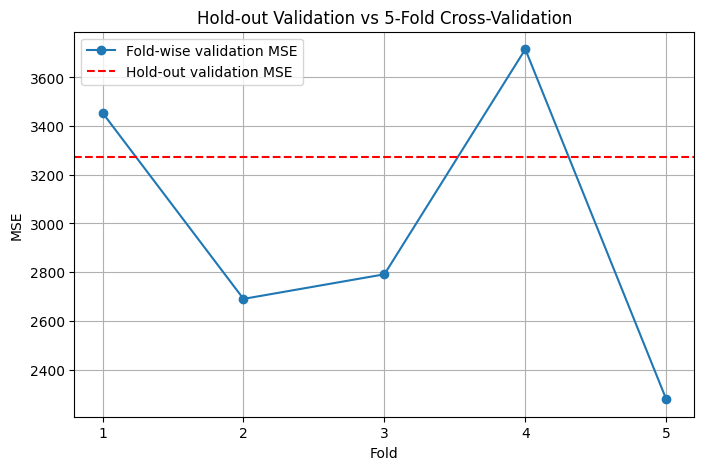

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    cv_results_df["Fold"],
    cv_results_df["Validation MSE"],
    marker="o",
    label="Fold-wise validation MSE"
)

plt.axhline(
    y=val_mse_holdout,
    color="red",
    linestyle="--",
    label="Hold-out validation MSE"
)

plt.xlabel("Fold")
plt.ylabel("MSE")
plt.title("Hold-out Validation vs 5-Fold Cross-Validation")
plt.xticks(cv_results_df["Fold"])
plt.legend()
plt.grid(True)
plt.show()

# 9) Fit the fixed model on the training + validation sets, then evaluate on the test set.

In [9]:
# Retrain the same fixed model on the full development set.
scaler_final = StandardScaler()
X_dev_std = scaler_final.fit_transform(X_dev)
X_test_std_final = scaler_final.transform(X_test)

ridge_final = Ridge(alpha=alpha_fixed)
ridge_final.fit(X_dev_std, y_dev)

y_test_pred = ridge_final.predict(X_test_std_final)
test_mse = mean_squared_error(y_test, y_test_pred)

print(f"Fixed alpha: {alpha_fixed}")
print(f"Test MSE: {test_mse:.4f}")

Fixed alpha: 1.0
Test MSE: 3148.1777


# 10) Summary

In [10]:
summary_df = pd.DataFrame({
    "Item": [
        "Hold-out validation MSE",
        "5-fold CV mean validation MSE",
        "5-fold CV std. of validation MSE",
        "Final test MSE"
    ],
    "Value": [
        val_mse_holdout,
        cv_val_mse_mean,
        cv_val_mse_std,
        test_mse
    ]
})

summary_df

,Item,Value
0,Hold-out validation MSE,3271.226895
1,5-fold CV mean validation MSE,2985.819989
2,5-fold CV std. of validation MSE,587.097209
3,Final test MSE,3148.177654
